# 124 — simplification evidence

Backs up (or corrects) each claim in the status update with run results. **Training logs only, no inference.**

- Metrics: first value of each key at `batch=2000` (ep200) in `runs/<run>/logs-rank0.txt`.
- **ID / OOD** = `metrics/eval/id|ood/iou08` (per-sample pooled). **ID_cat / OOD_cat** = the category means used in the bar plots (see below). **miss** = plain mean of the 65 per-split `metrics/eval/<box>/<split>/miss08` (no `cat/`, no `<box>/ood`). **split IoU** = plain mean of the per-split `iou08`, which is the only aggregate that exists for every run.
- Params: `transformer2: N parameters` in `runs/<run>.log`, otherwise `num_parameters` in the run's wandb `config.yaml`.
- All runs: 200 ep, seed 42, single seed. Differences below ~.01 in the aggregates, and below ~.05 on a single split, are within noise.
- Every claim has: what changed (flags, code), a table, an nb113-style per-split bar plot **with the reference**, the per-box / per-category / per-split deltas of the claim's key pair, and the exceptions.

In [1]:
import sys, json, glob, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
R = Path("/home/ethantu/workspace/good-vibrations")
BOXES = ("gastro", "plastic", "cardboard")
REF, REF_ID, REF_OOD = "s9-t2-ref-vase-200", 0.679, 0.377  # ref log predates the id/ood summary metrics -> hard-coded

def load(run):
    m = {}
    for line in open(R / "runs" / run / "logs-rank0.txt", errors="ignore"):
        if line.startswith("[metric][batch=2000]: "):
            k, _, v = line[22:].rpartition(": ")
            m.setdefault(k, float(v))  # duplicated lines: keep the first
    return m

def params(run):
    log = R / "runs" / f"{run}.log"
    if log.exists() and (h := re.findall(r"transformer2: ([\d,]+) parameters", log.read_text(errors="ignore"))): return int(h[-1].replace(",", ""))
    for f in sorted(glob.glob(str(R / f"wandb/run-*-{run}/files/config.yaml")))[::-1]:
        if (h := re.search(r"num_parameters:\s*\n\s*value: (\d+)", open(f).read())): return int(h[1])
    return np.nan

def splits(m, metric):  # {(box, split): value} per split, no cat/ and no per-box ood aggregate
    return {tuple(k.split("/")[2:4]): v for k, v in m.items() if k.startswith("metrics/eval/") and k.endswith("/" + metric)
            and k.count("/") == 4 and k.split("/")[2] in BOXES and k.split("/")[3] not in ("cat", "ood")}

def row(run):
    m = LOG.setdefault(run, load(run)); iou, miss = splits(m, "iou08"), splits(m, "miss08")
    r = dict(run=run, ID=m.get("metrics/eval/id/iou08", np.nan), OOD=m.get("metrics/eval/ood/iou08", np.nan), miss=np.mean(list(miss.values())),
             split_iou=np.mean(list(iou.values())), train=m.get("metrics/train/iou08", np.nan), params_M=params(run) / 1e6, n_splits=len(iou))
    for b in BOXES: r[b] = np.mean([v for (bb, _), v in iou.items() if bb == b])
    if run == REF: r["ID"], r["OOD"] = REF_ID, REF_OOD
    return r

LOG = {}
RUNS = """s9-t2-ref-vase-200 archA-v1 archA-ropeonly-v1 archA-nobox-v1 archA-samplez-v1 archA-samplestd-v1 archA-laserz-v1 archA-d256-l1024-v1
base4-v1 base4-noimom-v1 base4-box-v1 base4-laserz-v1 base4-drop10-v1 base-empty5-v1 base-edge-v1 base-logz-v1 base-logempty5-v1
base-area-v1 base-dice75-v1 base-tversky-v1 base-msdice-v1 base-tversky-ms-v1 base-combo-v1
s9-t2-freqcls-vase-200 s9-t2-lasercls-vase-200 s9-t2-cls-vase-200 freqcls-bandproj-v1 freqv-v1 laserv-v1 lasercls-laserproj-v1 cls-bandproj-v1""".split()
D = pd.DataFrame([row(r) for r in RUNS]).set_index("run")
COLS = ["ID", "OOD", "miss", "split_iou", "train", "params_M"]
def show(*runs, cols=None): return D.loc[list(runs), cols or COLS].round(3)
def delta(a, b): d = D.loc[b, ["ID", "OOD", "miss", "split_iou"]] - D.loc[a, ["ID", "OOD", "miss", "split_iou"]]; return " / ".join(f"Δ{k} {v:+.3f}" for k, v in d.items())
assert (D.n_splits == 65).all(), D.n_splits
print(f"{len(D)} runs, ref params {D.loc[REF, 'params_M']:.2f}M (from wandb config)")

# ---- nb113-style per-split plots, from the logs ----
sys.path.insert(0, str(R / "src9"))
from dataset import CATEGORIES                                      # {box: {category: [splits]}}, the same map nb113 uses
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
SPLITS = [("train", None), ("one-object", "id"), ("two-object", "multiple"), ("unseen position", "unseen-position"),
          ("unseen rotation", "rotated"), ("unseen object", "unseen-object"), ("unseen weight", "cylinder"),
          ("unseen speaker", "unseen-speaker"), ("unseen speckles", "unseen-laser"), ("lid", "lid")]
ID_CATS, OOD_CATS = {"id", "multiple"}, {"rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"}
RUN_COLOR = ["#3B6FB6", "#B04A5A", "#7A5FB0", "#2E8F83", "#C29237", "#555555"]
REF_COLOR = "#8C8C8C"

def per_split(run):  # one row per (box, split): iou08, miss08, category
    iou, miss = splits(LOG[run], "iou08"), splits(LOG[run], "miss08")
    return pd.DataFrame([(b, s, v, miss[(b, s)], CAT.get((b, s))) for (b, s), v in iou.items()], columns=["box", "split", "iou", "miss", "category"])
PS = {r: per_split(r) for r in RUNS}
assert all(PS[r].category.notna().all() for r in RUNS)

def id_ood(run):  # plain mean of the per-split iou08 over the splits in ID_CATS / OOD_CATS, every box
    d = PS[run]; return d[d.category.isin(ID_CATS)].iou.mean(), d[d.category.isin(OOD_CATS)].iou.mean()
D["ID_cat"], D["OOD_cat"] = zip(*[id_ood(r) for r in D.index])
COLS = ["ID", "OOD", "ID_cat", "OOD_cat", "miss", "split_iou", "train", "params_M"]

def stats(run):  # per SPLITS entry: per box, mean of its splits in that category -> mean and std over the boxes that have it; train = logged train iou08
    d, m, s = PS[run], [], []
    for _, cat in SPLITS:
        if cat is None: m.append(D.loc[run, "train"]); s.append(0.0); continue
        pb = d[d.category == cat].groupby("box").iou.mean()
        m.append(pb.mean() if len(pb) else np.nan); s.append(pb.std() if len(pb) > 1 else 0.0)
    return np.array(m), np.array(s)

def short(r): return r.replace("s9-t2-", "").replace("-vase-200", "")

def plot_runs(runs, title=""):
    """nb113 cell 5: one bar per run per split category, mean over boxes ± std over boxes; ref in grey"""
    x, w = np.arange(len(SPLITS)), 0.8 / len(runs)
    fig, ax = plt.subplots(figsize=(max(16, 3 + 0.32 * len(SPLITS) * len(runs)), 5), constrained_layout=True)
    k = 0
    for i, run in enumerate(runs):
        m, s = stats(run); i_, o_ = id_ood(run)
        c = REF_COLOR if run == REF else RUN_COLOR[k % len(RUN_COLOR)]; k += run != REF
        pos = x + (i - (len(runs) - 1) / 2) * w
        ax.bar(pos, np.nan_to_num(m), w, yerr=np.minimum(s, np.nan_to_num(m)), color=c, edgecolor="#222222", linewidth=0.4, capsize=2,
               label=f"{short(run)}@200ep · id {i_:.3f} · ood {o_:.3f}")
        for xi, v in zip(pos, m):
            if np.isnan(v): continue
            ax.text(xi, 0.008, f"{v:.3f}", rotation=90, ha="center", va="bottom", fontsize=10 if len(runs) <= 4 else 8, color="white" if v > 0.35 else "black")
    ax.set_xticks(x, [s[0] for s in SPLITS], rotation=45, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("IoU@0.08")
    ax.set_title((title + " · " if title else "") + "mean IoU@0.08 over boxes (± std over boxes)")
    ax.legend(title="category-mean IoU@0.08", frameon=False, title_fontsize=9, loc="upper right")
    plt.show()

def exceptions(a, b, k=3):
    """a -> b: per-box, per-category and per-split Δ IoU@.08 (b - a), top k splits each way, the 3 unseen-speaker splits"""
    M = PS[a].merge(PS[b], on=["box", "split", "category"], suffixes=("_a", "_b")); M["d"], M["dm"] = M.iou_b - M.iou_a, M.miss_b - M.miss_a
    f = lambda r: f"{r.box}/{r.split} {r.iou_a:.2f}→{r.iou_b:.2f} ({r.d:+.3f})"
    s = M.sort_values("d")
    print(f"{short(a)} → {short(b)}: mean Δ split IoU {M.d.mean():+.3f}, Δ miss {M.dm.mean():+.3f}")
    print("  per box  ΔIoU:", "  ".join(f"{bx} {M[M.box == bx].d.mean():+.3f}" for bx in BOXES), "| Δmiss:", "  ".join(f"{bx} {M[M.box == bx].dm.mean():+.3f}" for bx in BOXES))
    print("  per cat  ΔIoU:", "  ".join(f"{c} {v:+.3f}" for c, v in M.groupby("category").d.mean().sort_values().items()))
    print("  worst:", "; ".join(f(r) for r in s.head(k).itertuples()))
    print("  best: ", "; ".join(f(r) for r in s.tail(k)[::-1].itertuples()))
    print("  unseen speaker:", "; ".join(f(r) for r in M[M.category == "unseen-speaker"].itertuples()))

31 runs, ref params 34.92M (from wandb config)


**Reference:** `runs/s9-t2-ref-vase-200` exists, but its log predates the `metrics/eval/id|ood/iou08` summary keys, so in the tables **ID .679 / OOD .377 are hard-coded** (the user's numbers). Its miss, split IoU, train IoU and params (34.92M, from its wandb `config.yaml`) are read from the logs.
The same holds for the early `s9-t2-*cls-vase-200` runs: no pooled ID/OOD.

**How the bar plots are computed (`plot_runs`).** nb113 uses per-sample IoU from saved eval outputs; here only the logs are read, so everything is built from the per-split `metrics/eval/<box>/<split>/iou08` that *every* run (ref included) logs:
- each (box, split) is mapped to its category with `src9/dataset.py CATEGORIES` (same map as nb113); the x-axis is nb113's `SPLITS` (train = logged `metrics/train/iou08`, no error bar).
- **bar = mean over boxes** of each box's mean over its splits in that category; **error bar = std over boxes** (unseen speckles only exists for plastic + cardboard).
- **legend id / ood** = plain mean of per-split iou08 over all splits in `ID_CATS` = {id, multiple} / `OOD_CATS` = {rotated, cylinder, unseen-object, unseen-speaker, unseen-laser, lid}, all boxes. These are computed identically for every run, so the ref is comparable — but they weight every split equally and leave out unseen-position / control / etc., so they **differ from the pooled per-sample `metrics/eval/id|ood/iou08`** (columns `ID_cat` / `OOD_cat` vs `ID` / `OOD` in the tables).

**Exceptions (`exceptions(a, b)`)**: per-box, per-category and per-split Δ of the claim's key pair, the top 3 splits each way, and the three unseen-speaker splits. Single seed: one split moving by < .05 is noise-level.

## Claim 1 — positional info: RoPE replaced the learned additive band/laser embeddings
**What changed** (`--pos rope`, `src9/arch/transformer2.py`):
- **Ref (`pos="add"`, `rope=0`)**: band position = `freq_band_emb`, an MLP (1 → d → d) of the band's log10 centre frequency, added to every band token (`FreqEncoder`, l.83 / l.104); laser position = `laser_emb` (L × d learned, trunc-normal init) + `laser_pos` = Linear(16 → d) of 2D Fourier features of the laser (row, col) (`Encoder.__init__`, l.182–184), added to the band tokens and again to the laser tokens (l.211 / l.214). No rotary at all.
- **`pos="rope"`**: all three additive modules are dropped; `rope_1d` over the bands is applied to q/k in the freq-stage attention and `rope_2d` over the (row, col) laser grid in the laser stage (`pos="rope"` implies `rope=1`, l.167). Position is then only relative, inside attention.

**Runs:** `archA-v1` (additive) vs `archA-ropeonly-v1` (`--pos rope`), same Arch A otherwise; ref for context.

In [2]:
show(REF, "archA-v1", "archA-ropeonly-v1")

,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
archA-ropeonly-v1,0.628,0.349,0.559,0.262,0.163,0.392,0.723,25.337


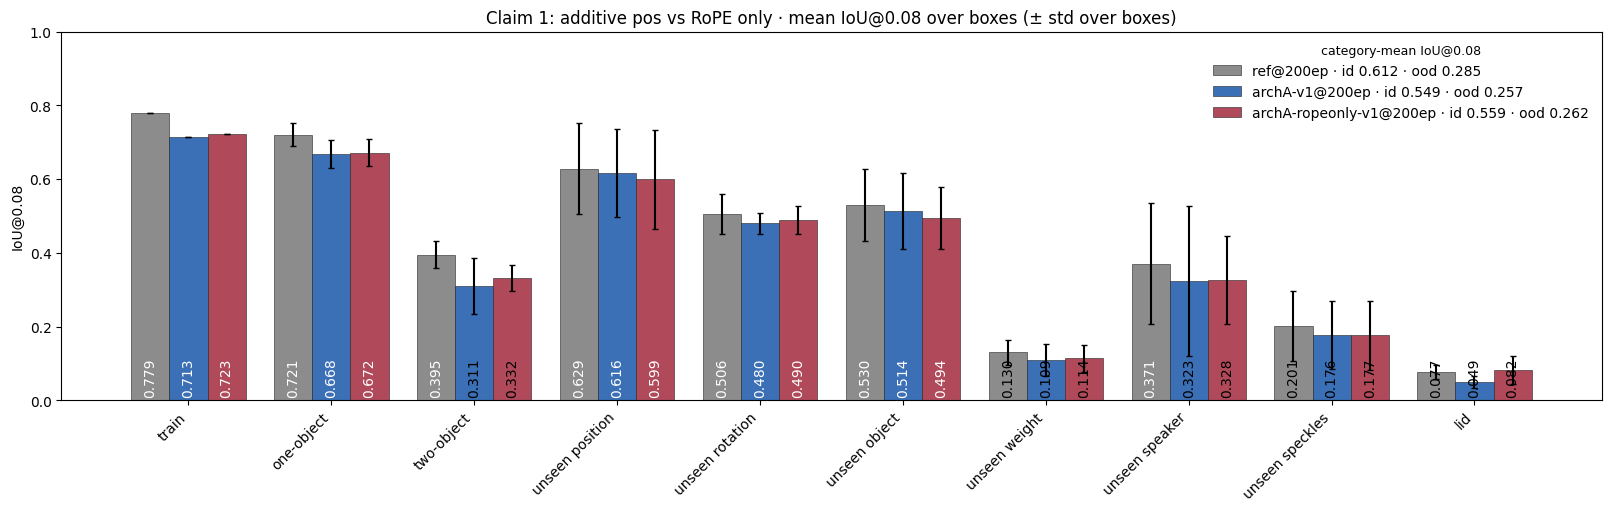

archA-v1 → archA-ropeonly-v1: mean Δ split IoU +0.004, Δ miss -0.006
  per box  ΔIoU: gastro +0.021  plastic -0.005  cardboard +0.002 | Δmiss: gastro -0.017  plastic +0.006  cardboard -0.008
  per cat  ΔIoU: unseen-rotated-object -0.037  broken -0.022  unseen-position -0.017  unseen-object -0.006  unseen-laser +0.000  unseen-angle +0.003  id +0.004  cylinder +0.004  unseen-speaker +0.004  control +0.006  rotated +0.013  multiple +0.021  lid +0.032
  worst: cardboard/vase-unseen-speaker-unseen 0.37→0.32 (-0.054); gastro/coffee-pot 0.63→0.58 (-0.051); cardboard/vase-laser-shifted-2 0.32→0.27 (-0.050)
  best:  gastro/cube-unseen-speaker-unseen 0.10→0.21 (+0.113); gastro/cube-with-lid 0.05→0.13 (+0.077); gastro/cube-vase 0.23→0.30 (+0.076)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.10→0.21 (+0.113); plastic/cube-unseen-speaker-unseen 0.50→0.45 (-0.046); cardboard/vase-unseen-speaker-unseen 0.37→0.32 (-0.054)


In [3]:
plot_runs([REF, "archA-v1", "archA-ropeonly-v1"], "Claim 1: additive pos vs RoPE only")
exceptions("archA-v1", "archA-ropeonly-v1")

**Verdict: supported.** RoPE-only ≈ additive (ID .623 → .628, OOD .349 → .349, miss .169 → .163) with 32k fewer params. A simplification, not a gain. `archA-v1` itself is below the ref (.623 vs .679 ID), see the final section.

**Exceptions.** The average hides a box split: gastro gains (+.021, miss −.017), plastic and cardboard are flat. The gastro gains are the multi-object / lid splits (cube-with-lid +.077, cube-vase +.076, two-cubes +.061) and gastro unseen speaker (.10 → .21, +.113). The losses are all ~ −.05 and scattered (cardboard vase-unseen-speaker −.054, gastro coffee-pot −.051, cardboard vase-laser-shifted-2 −.050, plastic unseen speaker −.046). Unseen speaker flips sign across boxes, so it's noise, not a RoPE effect.

## Claim 2 (+3) — auxiliary heads, outline channel and their losses removed; one mask output
Claim 3 (single image output) is folded in here: `--outline 0` went in with `--aux box_nobj` in the same base4 bundle, and both are "aux outputs + their losses".

The ref uses the transformer2 defaults `aux="all"`, `loss="full"`, `outline=1`. `total_loss` = mask loss + Σ `WEIGHTS[k]` · loss_k, with `WEIGHTS = dict(object=0.1, n_objects=0.1, com=1.0, area=0.1, box=0.1, edge=1.0, imoment=1.0, orient=1.0)` (l.250).

| | head / output | loss (code) | weight | base4 and later |
|---|---|---|---|---|
| object classifier | `object_head` mlp → n_known objects | CE, unseen objects ignored (`utils.aux_losses`) | 0.1 | **removed** |
| centre of mass | `com_head` mlp → 2K, sigmoid | per-object L1 `com_err`, / #objects | 1.0 | **removed** |
| area | `area_head` mlp → 1 | L1 on log(mask area fraction + 1/4096) (l.273) | 0.1 | **removed** |
| orientation | `orient_head` mlp → 2 | MSE to ecc · (cos 2θ, sin 2θ), single-object samples (`utils.orient_loss`) | 1.0 | **removed** |
| outline / edge | 2nd decoder channel (`Decoder(out_c=2)`) | `bce_dice` on `outline(mask)` (3×3 dilation − erosion) | 1.0 | **removed** (`--outline 0`, `out_c=1`) |
| box classifier | `box_head` | CE | 0.1 | **kept** |
| object count | `n_objects_head` → K+1 | CE | 0.1 | **kept** |

So with `--aux box_nobj --outline 0` the model outputs one mask channel + 2 tiny classifier heads (l.305 / l.320). The instance-moment loss (`imoment`, 1.0) is separate — it was still on in base4 (`bce_dice_imom`) and is claim 4.

**Evidence:** no clean ablation. `base4-v1` changed 7 things at once vs `archA-ropeonly-v1`: 2+2 → 4+4 layers, `--aux box_nobj`, `--outline 0`, `--box-emb 0`, `--norm box_z`, `--loss bce_dice_imom` (vs `full`: also adds Dice), microbatch 128 (`scripts/transformer2_base4.sh`). `archA-ropeonly-v1` is the closest pre-bundle run (pos already rope). Partial re-add of the outline: `base-edge-v1` = `base4-noimom-v1` + `--edge-w 4`, a 5× BCE weight on the true-outline pixels (no extra channel).

In [4]:
print(delta("archA-ropeonly-v1", "base4-v1")); print(delta("base4-noimom-v1", "base-edge-v1"))
show(REF, "archA-v1", "archA-ropeonly-v1", "base4-v1", "base4-noimom-v1", "base-edge-v1")

ΔID -0.025 / ΔOOD -0.001 / Δmiss -0.002 / Δsplit_iou -0.010
ΔID -0.001 / ΔOOD +0.004 / Δmiss -0.011 / Δsplit_iou +0.003


,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
archA-ropeonly-v1,0.628,0.349,0.559,0.262,0.163,0.392,0.723,25.337
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912
base4-noimom-v1,0.651,0.355,0.580,0.266,0.196,0.399,0.872,21.912
base-edge-v1,0.650,0.359,0.581,0.268,0.185,0.402,0.851,21.912


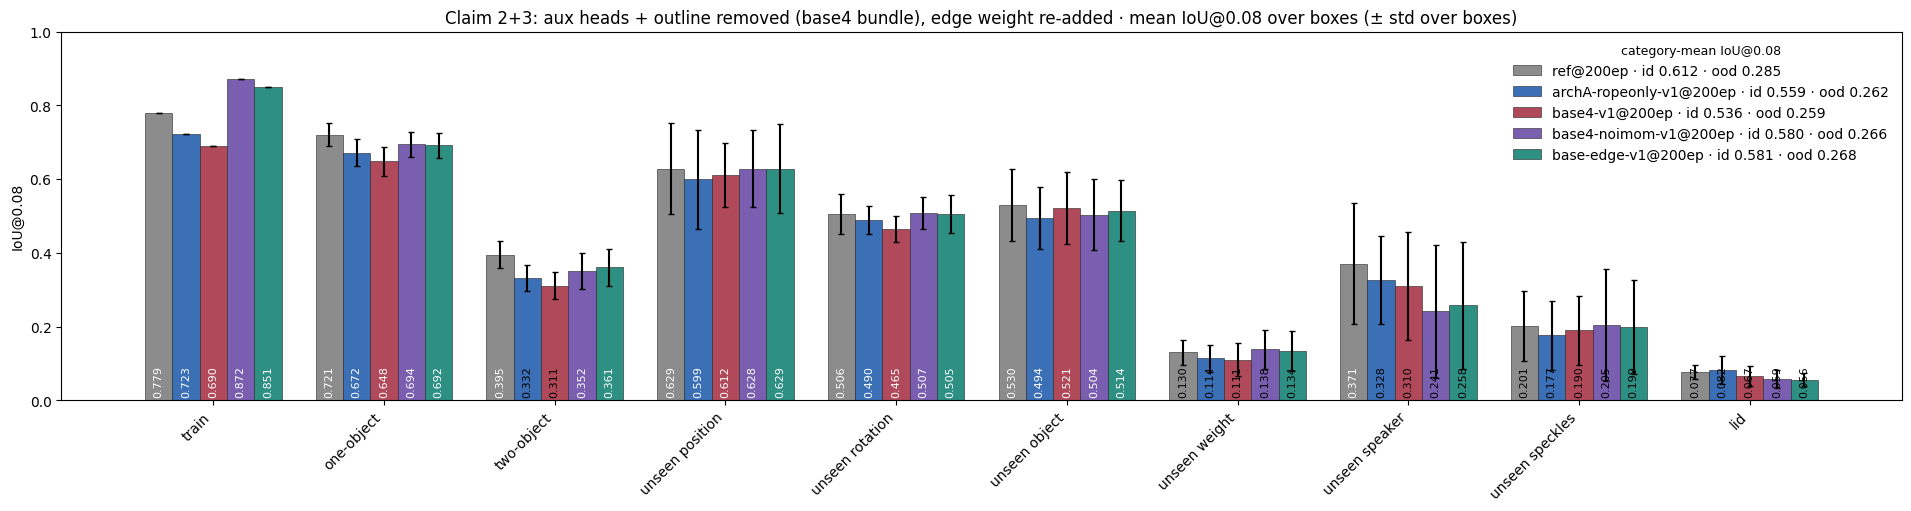

archA-ropeonly-v1 → base4-v1: mean Δ split IoU -0.010, Δ miss -0.002
  per box  ΔIoU: gastro -0.013  plastic -0.001  cardboard -0.016 | Δmiss: gastro -0.012  plastic -0.025  cardboard +0.021
  per cat  ΔIoU: unseen-angle -0.045  rotated -0.031  id -0.024  control -0.021  multiple -0.021  unseen-rotated-object -0.019  unseen-speaker -0.017  lid -0.015  cylinder -0.004  unseen-object +0.012  unseen-position +0.012  unseen-laser +0.013  broken +0.032
  worst: gastro/cube-with-lid 0.13→0.05 (-0.079); cardboard/glass-cup 0.55→0.48 (-0.076); cardboard/coffee-pot 0.58→0.52 (-0.057)
  best:  cardboard/vase-laser-shifted-2 0.27→0.34 (+0.074); cardboard/unseen-position 0.44→0.51 (+0.068); plastic/portable-charger 0.22→0.28 (+0.064)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.21→0.19 (-0.021); plastic/cube-unseen-speaker-unseen 0.45→0.47 (+0.023); cardboard/vase-unseen-speaker-unseen 0.32→0.27 (-0.054)

base4-noimom-v1 → base-edge-v1: mean Δ split IoU +0.003, Δ miss -0.011
  per box  ΔI

In [5]:
plot_runs([REF, "archA-ropeonly-v1", "base4-v1", "base4-noimom-v1", "base-edge-v1"], "Claim 2+3: aux heads + outline removed (base4 bundle), edge weight re-added")
exceptions("archA-ropeonly-v1", "base4-v1"); print()
exceptions("base4-noimom-v1", "base-edge-v1")

**Verdict: partly — the change is real, the evidence isn't.** The 7-way bundle went slightly *down* (ID .628 → .603, OOD .349 ≈ .349); no run isolates the aux heads or the outline channel. Re-adding the outline as a loss weight (`base-edge-v1`) is ≈ neutral (ID −.001, OOD +.004, miss −.011), consistent with "the outline channel wasn't needed" (also nb97: edge +.017 in src7).

**Exceptions.** The bundle's −.010 mean is concentrated on in-distribution and rotation: `unseen-angle` −.045, `rotated` −.031, `id` −.024, and cardboard/gastro (−.016 / −.013) while plastic is flat (−.001). The truly-OOD categories *improve* slightly: unseen-object +.012, unseen-laser +.013, unseen-position +.012 (best splits: cardboard vase-laser-shifted-2 +.074, cardboard unseen-position +.068, plastic portable-charger +.064). Worst: gastro cube-with-lid .13 → .05, cardboard glass-cup −.076, cardboard coffee-pot −.057. The edge weight moves no split by more than ±.05 (plastic cube-shifted-lasers-2 −.050, cardboard glass-cup-broken +.045), and lowers gastro miss by .024.

## Claim 4 — main loss: instance-moment loss removed → plain BCE + Dice
**What changed** (`--loss bce_dice_imom` → `--loss bce_dice`, `total_loss` l.266–280):
- **Instance-moment loss** (`utils.instance_moment_loss`, weight `imoment=1.0`): each pixel is assigned to the nearest true object (Mahalanobis distance + log det); within each object's cell the predicted mask's moments are matched to that object's by L1: 0.1 · |log area|, centroid (row, col), 100 · covariance (3 terms). One object = the whole image. It is on whenever `loss != "bce_dice"`, so the **ref had it too** (`loss="full"`).
- **Mask loss**: the ref (`full`) used **plain BCE** on the mask; the base4 bundle switched to `utils.bce_dice` = 0.5 BCE + 0.5 soft Dice (`dice_w=0.5`). So the current loss is BCE + Dice on the mask + 0.1 · (box CE + n_objects CE), nothing else.

**Runs:** `base4-v1` (`bce_dice_imom`) vs `base4-noimom-v1` (`bce_dice`), otherwise identical.

In [6]:
print(delta("base4-v1", "base4-noimom-v1")); show(REF, "base4-v1", "base4-noimom-v1")

ΔID +0.048 / ΔOOD +0.006 / Δmiss +0.035 / Δsplit_iou +0.018


,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912
base4-noimom-v1,0.651,0.355,0.580,0.266,0.196,0.399,0.872,21.912


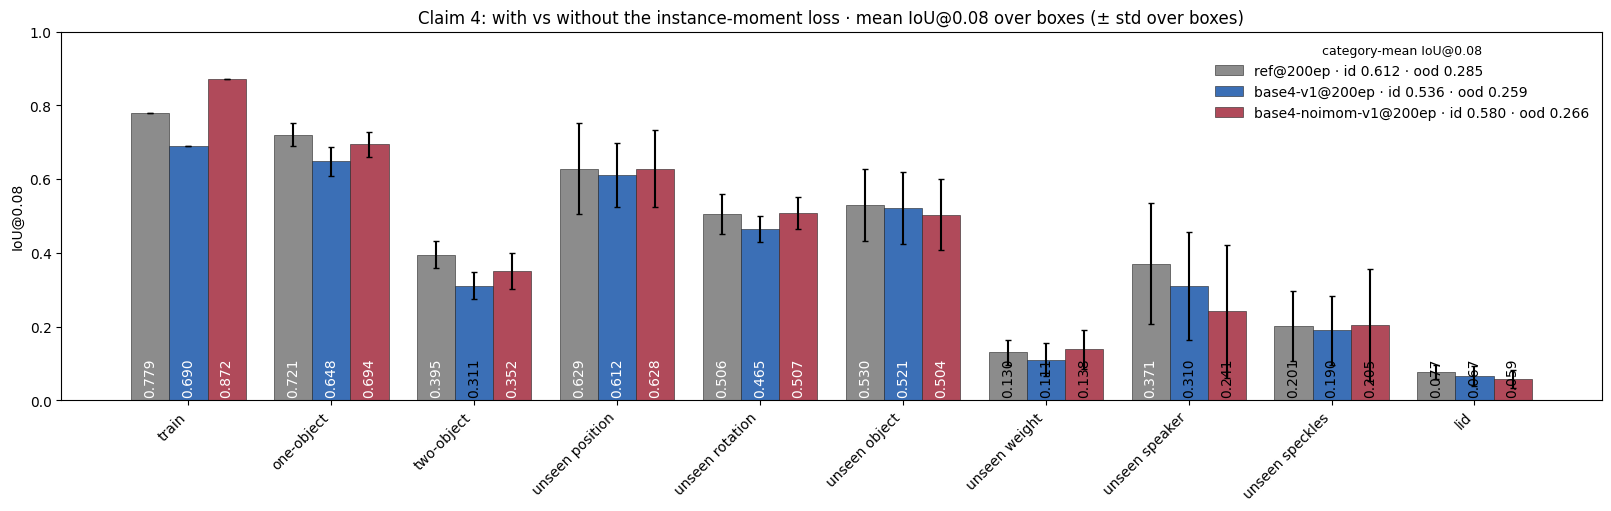

base4-v1 → base4-noimom-v1: mean Δ split IoU +0.018, Δ miss +0.035
  per box  ΔIoU: gastro +0.014  plastic +0.034  cardboard +0.008 | Δmiss: gastro +0.084  plastic +0.034  cardboard +0.006
  per cat  ΔIoU: unseen-rotated-object -0.082  unseen-speaker -0.069  broken -0.065  unseen-object -0.021  lid -0.008  unseen-angle +0.015  unseen-laser +0.016  unseen-position +0.016  control +0.029  cylinder +0.029  multiple +0.041  id +0.046  rotated +0.050
  worst: gastro/cube-unseen-speaker-unseen 0.19→0.05 (-0.140); cardboard/portable-charger 0.29→0.15 (-0.136); cardboard/portable-charger-sideways 0.33→0.24 (-0.082)
  best:  plastic/cube-shifted-lasers-1 0.37→0.47 (+0.101); cardboard/cube-rotated 0.39→0.49 (+0.100); cardboard/cube 0.38→0.46 (+0.082)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.19→0.05 (-0.140); plastic/cube-unseen-speaker-unseen 0.47→0.41 (-0.064); cardboard/vase-unseen-speaker-unseen 0.27→0.26 (-0.003)


In [7]:
plot_runs([REF, "base4-v1", "base4-noimom-v1"], "Claim 4: with vs without the instance-moment loss")
exceptions("base4-v1", "base4-noimom-v1")

**Verdict: supported on ID, with a cost.** ID +.048, OOD +.006, but mean miss rises .161 → .196 and train IoU jumps .690 → .872 — imom was acting as a regularizer that kept masks from vanishing; without it the model fits train much harder and drops more objects at eval.

**Exceptions.** The gain is in-distribution (id +.046, rotated +.050, multiple +.041; plastic +.034 is the biggest box). The pooled OOD +.006 hides a split by OOD type: imom removal **hurts unseen speaker (−.069), unseen rotated object (−.082), broken (−.065) and unseen object (−.021)**. Worst splits: gastro cube-unseen-speaker-unseen .19 → .05 (−.140), cardboard portable-charger .29 → .15 (−.136), cardboard portable-charger-sideways −.082. Gastro miss rises the most (+.084). Best: plastic cube-shifted-lasers-1 +.101, cardboard cube-rotated +.100, cardboard cube +.082.

## Claim 5 — box embedding removed, per-box norm kept
**What changed:**
- **Box embedding** (`--box-emb 0`): the ref adds `box_emb = nn.Embedding(n_boxes, d)` to every band token of every laser (`FreqEncoder`, l.84 / l.105). Removed → the network gets no box identity token.
- **Per-box norm kept**: the input is still standardized with that box's stats (`normalize()`, l.194: `box` / `box_z` with `cum_mean` / `cum_var` from all train samples of the box; later `empty5`, claims 6 / 8). So box information still enters through the normalization, just not as a learned token.
- Box-free alternatives tested: `sample_z` (z over the sample's (L, F, C)), `sample_std` (x / std of the sample), `laser_z` (z per (f, c) across the L lasers).

**Runs:** box emb: `archA-v1` vs `archA-nobox-v1`. Per-box norm: `archA-v1` (box) vs `archA-samplez-v1` / `archA-samplestd-v1` / `archA-laserz-v1`, and `base4-v1` (box_z) vs `base4-laserz-v1`.

In [8]:
show(REF, "archA-v1", "archA-nobox-v1", "archA-samplez-v1", "archA-samplestd-v1", "archA-laserz-v1", "base4-v1", "base4-laserz-v1")

,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
archA-nobox-v1,0.612,0.333,0.542,0.242,0.187,0.370,0.726,25.369
archA-samplez-v1,0.556,0.312,0.481,0.218,0.230,0.332,0.592,25.369
archA-samplestd-v1,0.556,0.310,0.483,0.215,0.228,0.329,0.590,25.369
archA-laserz-v1,0.584,0.324,0.480,0.235,0.232,0.351,0.750,25.369
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912
base4-laserz-v1,0.557,0.319,0.438,0.230,0.273,0.333,0.700,21.912


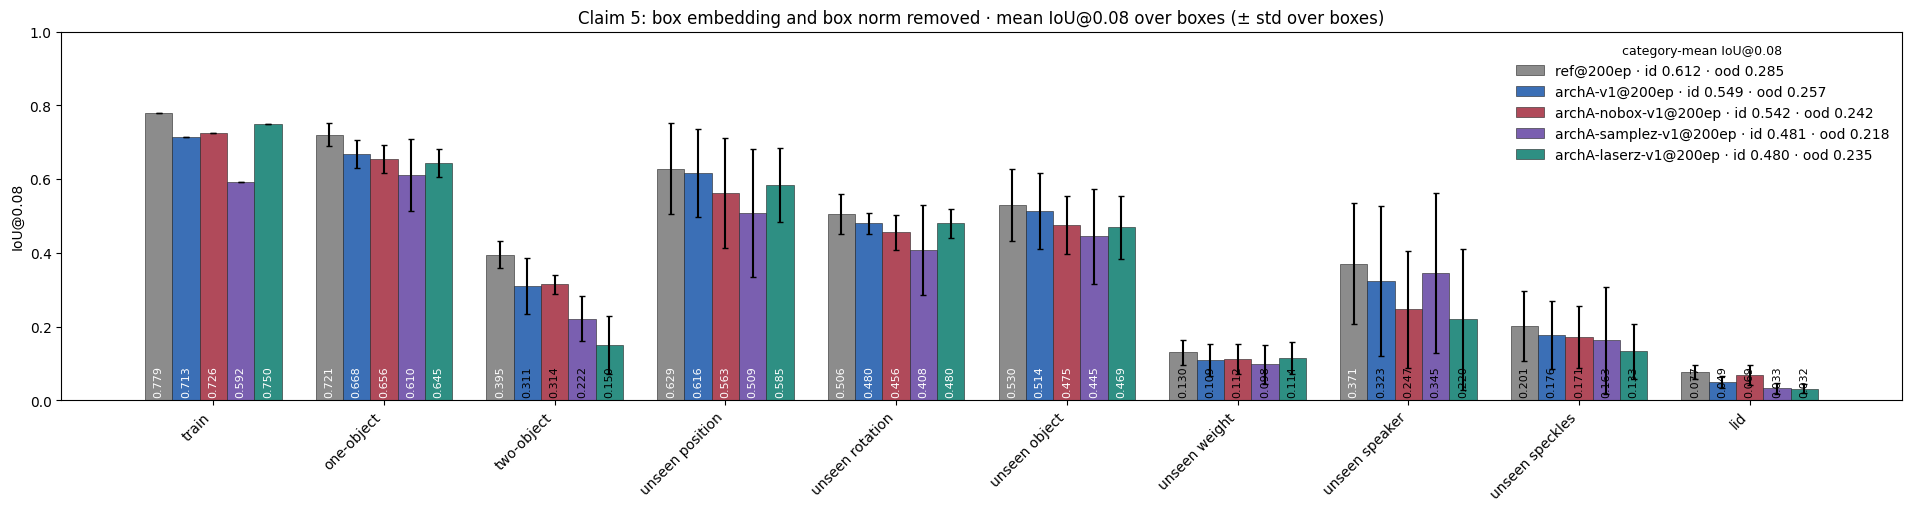

archA-v1 → archA-nobox-v1: mean Δ split IoU -0.017, Δ miss +0.018
  per box  ΔIoU: gastro +0.001  plastic -0.025  cardboard -0.021 | Δmiss: gastro +0.018  plastic +0.012  cardboard +0.023
  per cat  ΔIoU: broken -0.083  unseen-speaker -0.076  unseen-rotated-object -0.074  unseen-position -0.053  rotated -0.031  unseen-object -0.028  unseen-angle -0.023  control -0.020  id -0.013  unseen-laser -0.005  cylinder +0.001  multiple +0.004  lid +0.019
  worst: plastic/cube-unseen-speaker-unseen 0.50→0.37 (-0.125); cardboard/cube-rotated 0.41→0.31 (-0.097); cardboard/unseen-position 0.48→0.39 (-0.087)
  best:  gastro/two-cubes 0.22→0.29 (+0.074); gastro/cube-with-lid 0.05→0.10 (+0.050); gastro/cube-vase 0.23→0.28 (+0.049)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.10→0.07 (-0.031); plastic/cube-unseen-speaker-unseen 0.50→0.37 (-0.125); cardboard/vase-unseen-speaker-unseen 0.37→0.30 (-0.071)

archA-v1 → archA-samplez-v1: mean Δ split IoU -0.056, Δ miss +0.061
  per box  ΔIoU: gastro 

In [9]:
plot_runs([REF, "archA-v1", "archA-nobox-v1", "archA-samplez-v1", "archA-laserz-v1"], "Claim 5: box embedding and box norm removed")
exceptions("archA-v1", "archA-nobox-v1"); print()
exceptions("archA-v1", "archA-samplez-v1"); print()
exceptions("archA-v1", "archA-laserz-v1"); print()
exceptions("base4-v1", "base4-laserz-v1")

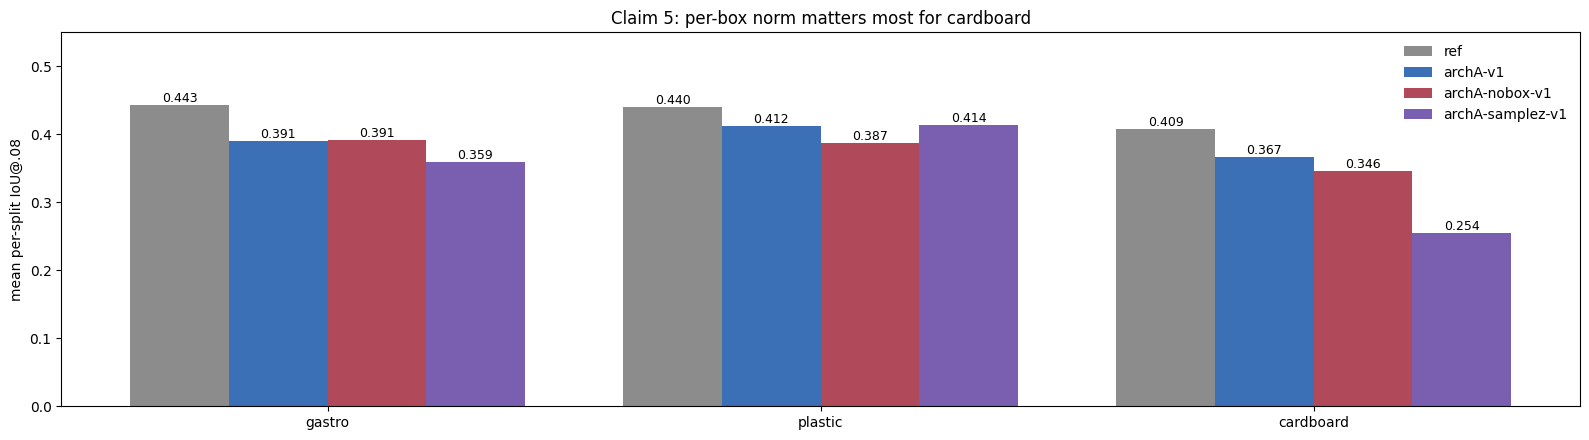

In [10]:
fig, ax = plt.subplots(figsize=(16, 4.5))
runs = [REF, "archA-v1", "archA-nobox-v1", "archA-samplez-v1"]
x, w = np.arange(len(BOXES)), 0.2
for i, r in enumerate(runs):
    b = ax.bar(x + (i - 1.5) * w, D.loc[r, list(BOXES)], w, label=short(r), color=REF_COLOR if r == REF else RUN_COLOR[i - 1]); ax.bar_label(b, fmt="%.3f", fontsize=9)
ax.set_xticks(x, BOXES); ax.set_ylabel("mean per-split IoU@.08"); ax.set_ylim(0, .55); ax.legend(frameon=False); ax.set_title("Claim 5: per-box norm matters most for cardboard")
plt.tight_layout(); plt.show()

**Verdict: supported.** Dropping the box embedding costs a little (ID −.011, OOD −.016, miss +.018) — an accepted trade. Dropping per-box norm costs a lot: sample_z / sample_std −.067 ID, laser_z −.039 ID (−.046 on base4).

**Exceptions.**
- **Box embedding:** the cost is plastic (−.025) and cardboard (−.021); gastro is flat (+.001) and its multi-object splits even improve (two-cubes +.074, cube-with-lid +.050, cube-vase +.049). The losses concentrate on OOD: unseen speaker −.076 (plastic cube-unseen-speaker-unseen .50 → .37, −.125), unseen rotated object −.074, unseen position −.053 (cardboard −.087).
- **Per-box norm → sample_z:** almost all cardboard (−.112, miss +.135), gastro −.031, **plastic ≈ 0 (+.002)**. Worst: cardboard tomato-sauce .63 → .37, soap-dispenser-rotated −.232, biscoff −.202, coffee-pot −.199. The one place sample_z *helps* is unseen speaker on gastro (+.092) and plastic (+.097), plus plastic portable-charger (+.105) — but cardboard unseen speaker drops −.125.
- **laser_z** fails differently: it is even across boxes but wrecks **two-object** samples (multiple −.16; on base4 −.257, gastro cube-vase .30 → .00) — z-scoring across lasers removes the level differences that separate two objects.

## Claim 6 — input normalization: per-box empty-scan standardization; per-sample std alone hurt
**Current (`--norm empty5`, `normalize()` l.198):** `x_norm = (x − mean_box[box]) / std_box[box]`, with mean / std of shape (3 boxes, L lasers, F freq bins, C=2 channels) computed from **5 empty-box train scans per box** (`src9/dataset.py` l.296–314, std floored at 0.1 × the box's median std). No per-sample rescaling after it. This performs like the same standardization with stats over **all** train samples of the box (`--norm box`, `cum_mean` / `cum_var`), see claim 8.

The other norms (`normalize()` l.194–204): `box` = (x − cum_mean[box]) · cum_var[box]^−½; `box_z` = `box`, then z over the sample's (L, F, C); `sample_std` = x / std of the sample (no box stats); `sample_z`; `laser_z`; `log_z` / `log_empty5` = log magnitude variants.

**Runs:** per-sample std alone: `archA-v1` (box) vs `archA-samplestd-v1`. Per-sample z on top of box stats: `base4-v1` (box_z) vs `base4-box-v1` (box). Current: `base-empty5-v1`; log variants `base-logz-v1`, `base-logempty5-v1`.

In [11]:
show(REF, "archA-v1", "archA-samplestd-v1", "base4-v1", "base4-box-v1", "base4-noimom-v1", "base-empty5-v1", "base-logz-v1", "base-logempty5-v1")

,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
archA-samplestd-v1,0.556,0.310,0.483,0.215,0.228,0.329,0.590,25.369
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912
base4-box-v1,0.601,0.346,0.520,0.260,0.168,0.378,0.676,21.912
base4-noimom-v1,0.651,0.355,0.580,0.266,0.196,0.399,0.872,21.912
base-empty5-v1,0.655,0.364,0.587,0.277,0.184,0.409,0.848,21.912
base-logz-v1,0.625,0.325,0.552,0.240,0.227,0.375,0.891,21.912
base-logempty5-v1,0.620,0.336,0.551,0.249,0.204,0.381,0.907,21.912


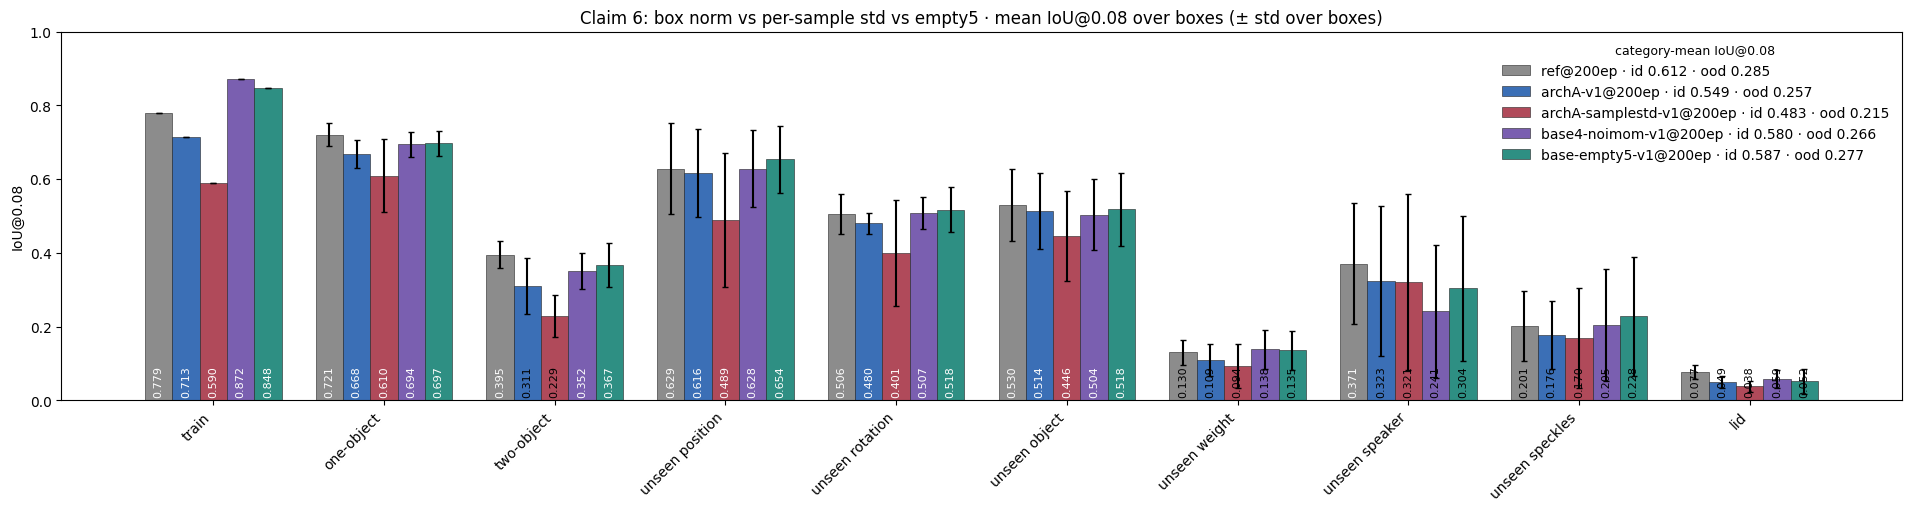

archA-v1 → archA-samplestd-v1: mean Δ split IoU -0.058, Δ miss +0.059
  per box  ΔIoU: gastro -0.034  plastic +0.003  cardboard -0.118 | Δmiss: gastro +0.036  plastic -0.011  cardboard +0.124
  per cat  ΔIoU: unseen-angle -0.173  unseen-rotated-object -0.172  unseen-position -0.127  rotated -0.117  unseen-object -0.098  multiple -0.082  broken -0.066  id -0.059  control -0.058  cylinder -0.016  lid -0.011  unseen-laser -0.006  unseen-speaker -0.002
  worst: cardboard/tomato-sauce 0.63→0.38 (-0.257); cardboard/soap-dispenser-rotated 0.53→0.28 (-0.253); cardboard/coffee-pot 0.55→0.34 (-0.204)
  best:  plastic/portable-charger 0.24→0.34 (+0.103); plastic/cube-unseen-speaker-unseen 0.50→0.60 (+0.100); gastro/cube-unseen-speaker-unseen 0.10→0.16 (+0.058)


  unseen speaker: gastro/cube-unseen-speaker-unseen 0.10→0.16 (+0.058); plastic/cube-unseen-speaker-unseen 0.50→0.60 (+0.100); cardboard/vase-unseen-speaker-unseen 0.37→0.21 (-0.163)

base4-v1 → base4-box-v1: mean Δ split IoU -0.003, Δ miss +0.007
  per box  ΔIoU: gastro -0.003  plastic -0.006  cardboard -0.001 | Δmiss: gastro +0.013  plastic +0.013  cardboard -0.002
  per cat  ΔIoU: multiple -0.053  unseen-laser -0.011  unseen-object -0.006  control -0.006  cylinder +0.003  rotated +0.003  id +0.003  unseen-position +0.006  unseen-rotated-object +0.007  unseen-angle +0.008  lid +0.017  unseen-speaker +0.019  broken +0.030
  worst: gastro/cube-vase 0.30→0.20 (-0.101); cardboard/glass-cup 0.48→0.41 (-0.062); cardboard/two-cubes 0.24→0.18 (-0.060)
  best:  cardboard/vase-unseen-speaker-unseen 0.27→0.34 (+0.075); gastro/cube-with-lid 0.05→0.11 (+0.064); gastro/unseen-position 0.67→0.70 (+0.035)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.19→0.18 (-0.014); plastic/cube-unseen-spe

In [12]:
plot_runs([REF, "archA-v1", "archA-samplestd-v1", "base4-noimom-v1", "base-empty5-v1"], "Claim 6: box norm vs per-sample std vs empty5")
exceptions("archA-v1", "archA-samplestd-v1"); print()
exceptions("base4-v1", "base4-box-v1")

**Verdict: supported (after correcting the earlier "each sample normalized to std = 1" wording).**
- Per-sample std alone hurts badly: `archA-samplestd-v1` .556 vs `archA-v1` .623 ID.
- A per-sample z *on top of* box stats is neutral: `base4-v1` (box_z) .603/.349 vs `base4-box-v1` (box only) .601/.346.
- The current best, `base-empty5-v1` (.655/.364), uses per-box empty-scan mean/std with no per-sample step.
- Log magnitude hurt: `base-logz-v1` .625/.325, `base-logempty5-v1` .620/.336.

**Exceptions.** `sample_std` has the same fingerprint as `sample_z` (claim 5): cardboard −.118 (miss +.124), gastro −.034, plastic +.003; worst cardboard tomato-sauce −.257, soap-dispenser-rotated −.253, coffee-pot −.204, cube-rotated −.204. **Unseen speaker improves with per-sample std on plastic (+.100) and gastro (+.058) but drops −.163 on cardboard.** The box_z → box swap is ≈ 0 on average but not on two-object samples (multiple −.053, gastro cube-vase .30 → .20); cardboard vase-unseen-speaker goes the other way (+.075).

## Claim 7 — hidden dim + latent: bigger helped, at 2× params, so we kept 128 / 256
**What changed:** `--d 256 --latent-dim 1024` (vs `--d 128 --latent-dim 256`), one combined change: d = the token width in both encoder stages; latent = the Arch A bottleneck `u` (`LaserEncoder`, l.138–154). Microbatch 128 instead of 256 for memory (same batch 1024).

**Runs:** `archA-v1` (d 128, latent 256) vs `archA-d256-l1024-v1` (d 256, latent 1024). Never repeated on the base4 / empty5 base.

In [13]:
print(delta("archA-v1", "archA-d256-l1024-v1")); show(REF, "archA-v1", "archA-d256-l1024-v1")

ΔID +0.030 / ΔOOD +0.011 / Δmiss -0.016 / Δsplit_iou +0.022


,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
archA-d256-l1024-v1,0.652,0.360,0.585,0.274,0.153,0.410,0.752,52.520


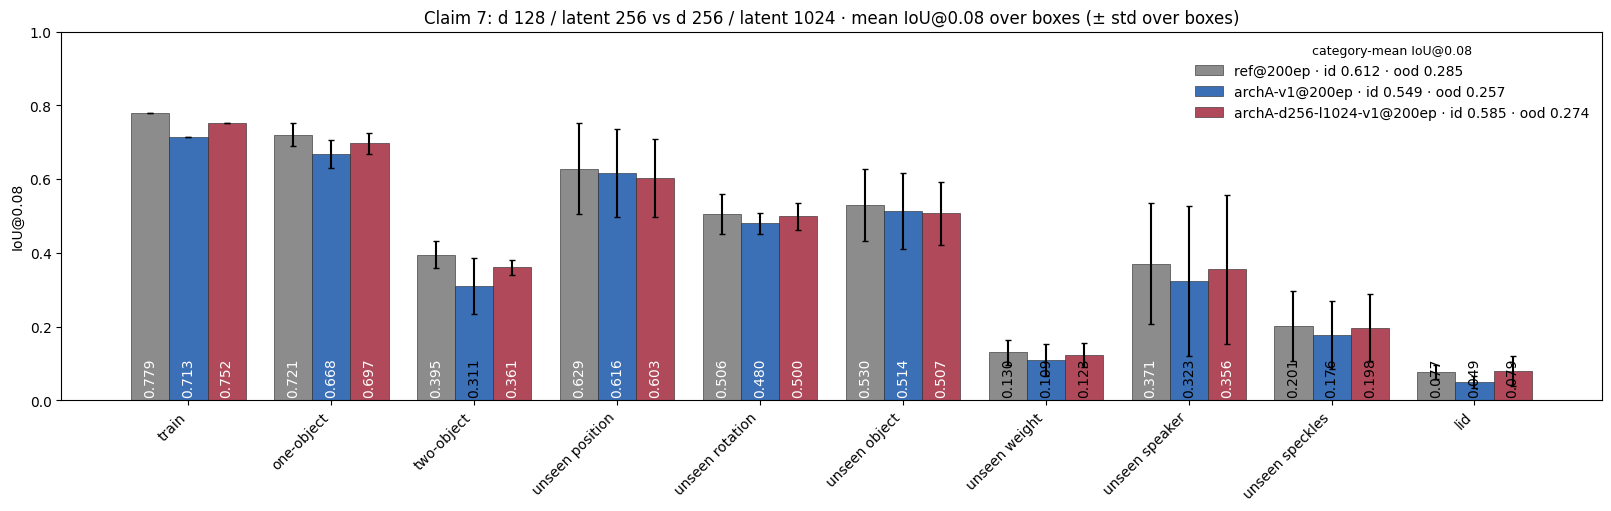

archA-v1 → archA-d256-l1024-v1: mean Δ split IoU +0.022, Δ miss -0.016
  per box  ΔIoU: gastro +0.040  plastic +0.008  cardboard +0.023 | Δmiss: gastro -0.027  plastic -0.001  cardboard -0.022
  per cat  ΔIoU: unseen-position -0.014  unseen-object -0.000  broken +0.010  cylinder +0.013  unseen-angle +0.019  unseen-laser +0.022  unseen-rotated-object +0.023  id +0.028  lid +0.029  control +0.030  rotated +0.030  unseen-speaker +0.033  multiple +0.050
  worst: cardboard/glass-cup 0.56→0.48 (-0.083); cardboard/coffee-pot 0.55→0.51 (-0.035); plastic/unseen-position 0.68→0.65 (-0.034)
  best:  gastro/cube-vase 0.23→0.37 (+0.137); cardboard/cube-rotated 0.41→0.51 (+0.103); gastro/two-cubes 0.22→0.31 (+0.090)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.10→0.14 (+0.037); plastic/cube-unseen-speaker-unseen 0.50→0.53 (+0.037); cardboard/vase-unseen-speaker-unseen 0.37→0.40 (+0.025)


In [14]:
plot_runs([REF, "archA-v1", "archA-d256-l1024-v1"], "Claim 7: d 128 / latent 256 vs d 256 / latent 1024")
exceptions("archA-v1", "archA-d256-l1024-v1")

**Verdict:** increasing the hidden dim (128 → 256) together with the latent (256 → 1024) helped (+.03 ID IoU: ID +.029, OOD +.011, miss −.016) but at a cost (2× params, 25.4M → 52.5M), so we kept 128 / 256.

**Exceptions.** The gain is broad (every category ≥ −.014) and largest on two-object samples (multiple +.050: gastro cube-vase .23 → .37, gastro two-cubes +.090) and in gastro (+.040 vs plastic +.008). Unseen speaker improves on all three boxes (+.025 to +.037). The only regressions: cardboard glass-cup −.083, cardboard coffee-pot −.035, plastic unseen-position −.034.

## Claim 8 — 5 empty-box scans ≈ full train stats
`x_norm = (x − mean_box[box]) / std_box[box]`, mean/std of shape (3 boxes, L, F, C=2) from 5 empty-box scans of that box.

**Code check:**
- `src9/dataset.py`: `empty5 = {b: sorted(np.random.default_rng(0).choice(ids, min(5, len(ids)), replace=False))}` over each box's **empty train scans** (`n_objects == 0`), so a fresh `rng(0)` per box; mean/std per (box, laser, bin, channel); `e5_std = max(e5_std, 0.1 × median(e5_std of that box))` — the std is floored at 0.1× the box median. Indices are saved as `info["empty5_idx"]`.
- `src9/arch/transformer2.py normalize()`: `empty5` → `(x - empty5_mean[box]) / empty5_std[box]`, nothing else. `box`/`box_z` use `cum_mean`/`cum_var` from **all** train samples of the box.

No single clean pair, so a two-step argument:

**(a)** full train stats + per-sample z (`base4-noimom-v1`, `box_z`) vs 5 empty scans (`base-empty5-v1`, `empty5`) — differ in stats source *and* the per-sample z.
**(b)** the per-sample z alone is ≈ neutral: `base4-v1` (`box_z`) vs `base4-box-v1` (`box`), same base, both with imom.

In [15]:
print("(a)", delta("base4-noimom-v1", "base-empty5-v1")); print("(b)", delta("base4-v1", "base4-box-v1")); show(REF, "base4-noimom-v1", "base-empty5-v1", "base4-v1", "base4-box-v1", cols=COLS + list(BOXES))

(a) ΔID +0.004 / ΔOOD +0.009 / Δmiss -0.012 / Δsplit_iou +0.010
(b) ΔID -0.002 / ΔOOD -0.003 / Δmiss +0.007 / Δsplit_iou -0.003


,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M,gastro,plastic,cardboard
run,,,,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923,0.443,0.440,0.409
base4-noimom-v1,0.651,0.355,0.580,0.266,0.196,0.399,0.872,21.912,0.414,0.439,0.361
base-empty5-v1,0.655,0.364,0.587,0.277,0.184,0.409,0.848,21.912,0.429,0.455,0.364
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912,0.399,0.406,0.353
base4-box-v1,0.601,0.346,0.520,0.260,0.168,0.378,0.676,21.912,0.396,0.400,0.352


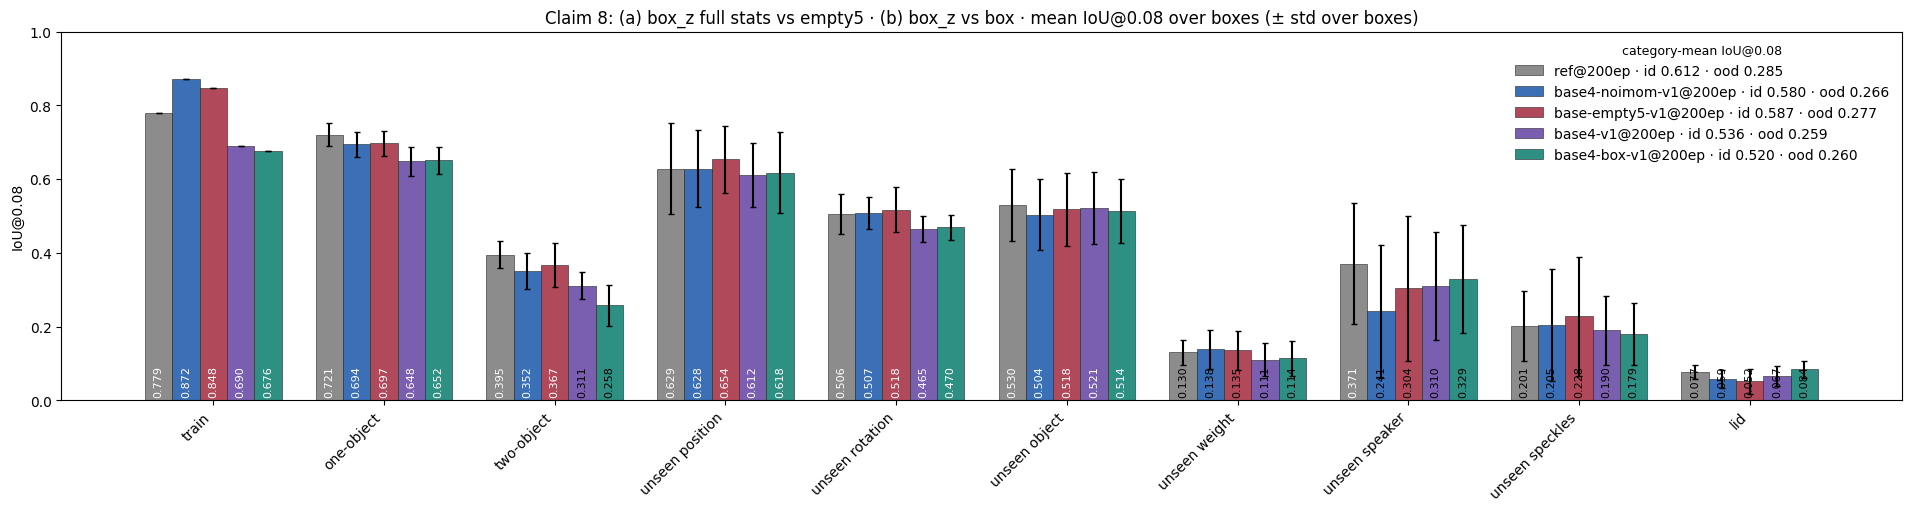

base4-noimom-v1 → base-empty5-v1: mean Δ split IoU +0.010, Δ miss -0.012
  per box  ΔIoU: gastro +0.015  plastic +0.016  cardboard +0.003 | Δmiss: gastro -0.029  plastic -0.016  cardboard +0.001
  per cat  ΔIoU: broken -0.058  unseen-rotated-object -0.015  lid -0.007  cylinder -0.003  id +0.003  unseen-angle +0.007  rotated +0.010  unseen-object +0.012  multiple +0.015  control +0.017  unseen-laser +0.023  unseen-position +0.026  unseen-speaker +0.063
  worst: cardboard/glass-cup-broken 0.32→0.26 (-0.058); plastic/cube-with-lid 0.03→0.01 (-0.020); cardboard/glass-cup 0.42→0.40 (-0.020)
  best:  plastic/cube-unseen-speaker-unseen 0.41→0.50 (+0.095); gastro/cube-unseen-speaker-unseen 0.05→0.11 (+0.060); plastic/cube-shifted-lasers-2 0.36→0.41 (+0.057)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.05→0.11 (+0.060); plastic/cube-unseen-speaker-unseen 0.41→0.50 (+0.095); cardboard/vase-unseen-speaker-unseen 0.26→0.30 (+0.033)


In [16]:
plot_runs([REF, "base4-noimom-v1", "base-empty5-v1", "base4-v1", "base4-box-v1"], "Claim 8: (a) box_z full stats vs empty5 · (b) box_z vs box")
exceptions("base4-noimom-v1", "base-empty5-v1")

**Verdict: supported (single seed).** (a) empty5 .655/.364 vs box_z .651/.355 — equal or slightly better, on every box (gastro +.015, plastic +.016, cardboard +.003). (b) the per-sample z is neutral (.603/.349 vs .601/.346), so the gap in (a) is not the z step. Together: 5 empty scans ≈ full train stats, even slightly better on OOD.

**Not tested:** a clean run with full train stats and *no* per-sample z on the noimom base (`--norm box` + `bce_dice`), and any per-seed repeat of empty5 vs box.

**Exceptions.** (a) empty5 is ≥ the full-stat run nearly everywhere: no split drops by more than .02 except cardboard glass-cup-broken (−.058). The biggest gains are **unseen speaker on every box** (plastic .41 → .50, +.095; gastro +.060; cardboard +.033), plus plastic cube-shifted-lasers-2 +.057 and gastro cube-without-lid +.056. Cardboard is the box that gains least (+.003 vs +.015 / +.016). (b) see claim 6: box_z vs box only differs on two-object samples.

## Other major changes since the reference

### (a) Trajectory ref → current best

In [17]:
TRAJ = [(REF, "ref: gated bands + flatten readout, additive pos, box emb, box norm, 2+2 layers, all aux + outline + full loss"),
        ("s9-t2-freqcls-vase-200", "[cls] attempt: freq [cls] readout (no ID/OOD logged)"),
        ("s9-t2-cls-vase-200", "[cls] attempt: freq + laser [cls] (no ID/OOD logged)"),
        ("freqcls-bandproj-v1", "[cls] attempt: freq [cls] + per-band projection"),
        ("freqv-v1", "[cls] attempt: freq [cls] + per-band V readout"),
        ("archA-v1", "Arch A readout: one 256-d latent replaces gates + flatten"),
        ("archA-ropeonly-v1", "+ RoPE only (no additive band/laser embeddings)"),
        ("base4-v1", "+ 4+4 layers, aux box_nobj, outline 0, no box emb, box_z norm, bce_dice_imom (bundle)"),
        ("base4-noimom-v1", "− imom loss"),
        ("base-empty5-v1", "norm empty5 (5 empty scans, no per-sample z) = current best")]
T = D.loc[[r for r, _ in TRAJ], ["ID", "OOD", "miss", "split_iou", "params_M", "train"]].round(3)
T.insert(0, "change", [c for _, c in TRAJ]); T

,change,ID,OOD,miss,split_iou,params_M,train
run,,,,,,,
s9-t2-ref-vase-200,"ref: gated bands + flatten readout, additive p...",0.679,0.377,0.150,0.427,34.923,0.779
s9-t2-freqcls-vase-200,[cls] attempt: freq [cls] readout (no ID/OOD l...,NaN,NaN,0.204,0.332,34.611,0.597
s9-t2-cls-vase-200,[cls] attempt: freq + laser [cls] (no ID/OOD l...,NaN,NaN,0.420,0.183,21.635,0.367
freqcls-bandproj-v1,[cls] attempt: freq [cls] + per-band projection,0.606,0.344,0.160,0.377,34.896,0.658
freqv-v1,[cls] attempt: freq [cls] + per-band V readout,0.628,0.364,0.158,0.399,35.205,0.691
archA-v1,Arch A readout: one 256-d latent replaces gate...,0.623,0.349,0.169,0.387,25.369,0.713
archA-ropeonly-v1,+ RoPE only (no additive band/laser embeddings),0.628,0.349,0.163,0.392,25.337,0.723
base4-v1,"+ 4+4 layers, aux box_nobj, outline 0, no box ...",0.603,0.349,0.161,0.381,21.912,0.690
base4-noimom-v1,− imom loss,0.651,0.355,0.196,0.399,21.912,0.872


### (b) ID / OOD along the trajectory

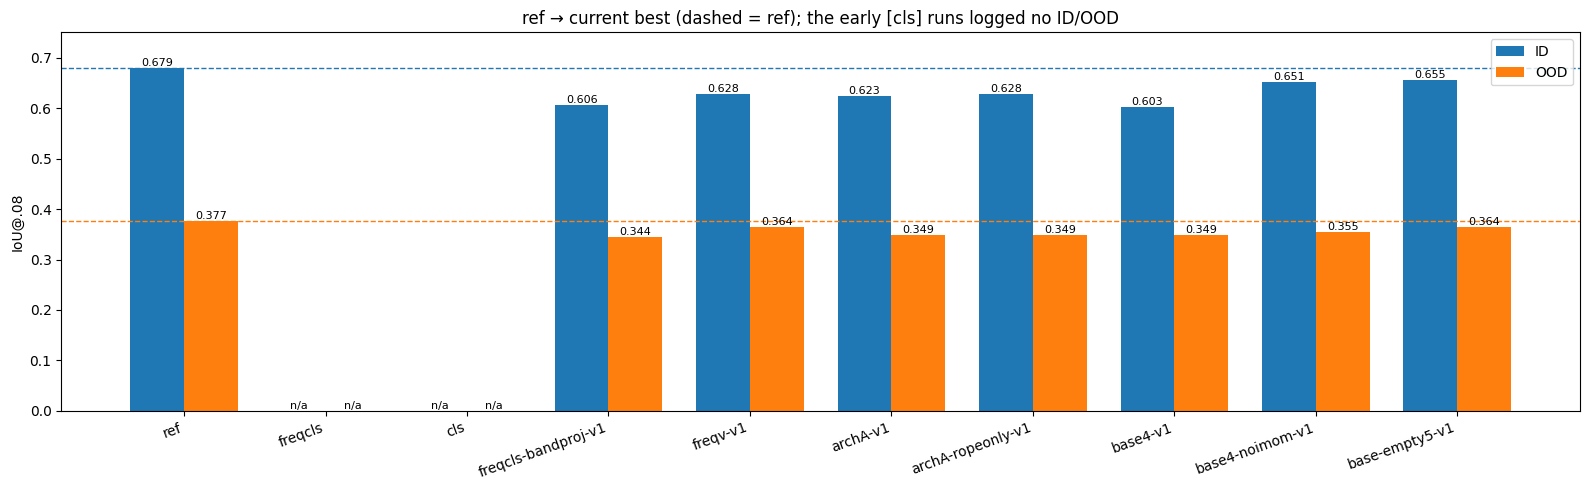

In [18]:
fig, ax = plt.subplots(figsize=(16, 5))
x, w = np.arange(len(T)), 0.38
for i, (k, c) in enumerate((("ID", "C0"), ("OOD", "C1"))):
    b = ax.bar(x + (i - .5) * w, T[k].fillna(0), w, label=k, color=c); ax.bar_label(b, labels=[f"{v:.3f}" if v == v else "n/a" for v in T[k]], fontsize=8)
for k, c in (("ID", "C0"), ("OOD", "C1")): ax.axhline(T.loc[REF, k], color=c, ls="--", lw=1)
ax.set_xticks(x, [r.replace("s9-t2-", "").replace("-vase-200", "") for r in T.index], rotation=20, ha="right"); ax.set_ylabel("IoU@.08"); ax.set_ylim(0, .75)
ax.legend(); ax.set_title("ref → current best (dashed = ref); the early [cls] runs logged no ID/OOD"); plt.tight_layout(); plt.show()

### (c) Other changes not in the list (each checked against scripts / logs)

In [19]:
show("archA-v1", "base4-v1", "base4-drop10-v1", "base4-noimom-v1", "base-area-v1", "base-dice75-v1", "base-tversky-v1", "base-msdice-v1", "base-edge-v1", "base-tversky-ms-v1", "base-combo-v1", "base-logz-v1", "base-logempty5-v1", "base-empty5-v1")

,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
archA-v1,0.623,0.349,0.549,0.257,0.169,0.387,0.713,25.369
base4-v1,0.603,0.349,0.536,0.259,0.161,0.381,0.690,21.912
base4-drop10-v1,0.572,0.338,0.505,0.245,0.169,0.363,0.558,21.912
base4-noimom-v1,0.651,0.355,0.580,0.266,0.196,0.399,0.872,21.912
base-area-v1,0.657,0.357,0.586,0.268,0.193,0.405,0.863,21.912
base-dice75-v1,0.654,0.352,0.585,0.265,0.191,0.400,0.879,21.912
base-tversky-v1,0.650,0.359,0.583,0.266,0.188,0.401,0.817,21.912
base-msdice-v1,0.637,0.354,0.571,0.262,0.202,0.396,0.787,21.912
base-edge-v1,0.650,0.359,0.581,0.268,0.185,0.402,0.851,21.912


- **Arch A readout** replaced gated bands + the 12,800×1024 flatten with one 256-d latent (`--readout archA --latent-dim 256`). It cost ID: `archA-v1` .623/.349 vs ref .679/.377 (and 34.9M → 25.4M). Note: `scripts/transformer2_archA.sh` says `--latent-dim 128` but `runs/archA-v1/args.json` has 256 (and the same param count as the latent-256 ablations), so trust 256.
- **2+2 → 4+4 layers** — only inside the base4 bundle, no clean ablation.
- **empty5 norm** (5 empty scans instead of full train stats) — the current best, see claim 8.
- **Params 34.9M → 21.9M** (−37%).
- **Loss tweaks ≈ no effect** on `base4-noimom-v1` (.651/.355): area .657/.357, dice75 .654/.352, tversky .650/.359, ms-dice .637/.354, edge .650/.359. Combining them hurt: tversky+ms-dice .602/.348, combo (log_empty5 + tversky + ms-dice) .584/.334.
- **Log magnitude hurt**: log_z .625/.325, log_empty5 .620/.336.
- **10% laser/band token dropout hurt**: `base4-drop10-v1` .572/.338 vs `base4-v1` .603/.349.

### (d) Bottom line

In [20]:
print(delta(REF, "base-empty5-v1"), f"| params {D.loc[REF, 'params_M']:.1f}M -> {D.loc['base-empty5-v1', 'params_M']:.1f}M"); show(REF, "base-empty5-v1")

ΔID -0.024 / ΔOOD -0.013 / Δmiss +0.034 / Δsplit_iou -0.018 | params 34.9M -> 21.9M


,ID,OOD,ID_cat,OOD_cat,miss,split_iou,train,params_M
run,,,,,,,,
s9-t2-ref-vase-200,0.679,0.377,0.612,0.285,0.150,0.427,0.779,34.923
base-empty5-v1,0.655,0.364,0.587,0.277,0.184,0.409,0.848,21.912


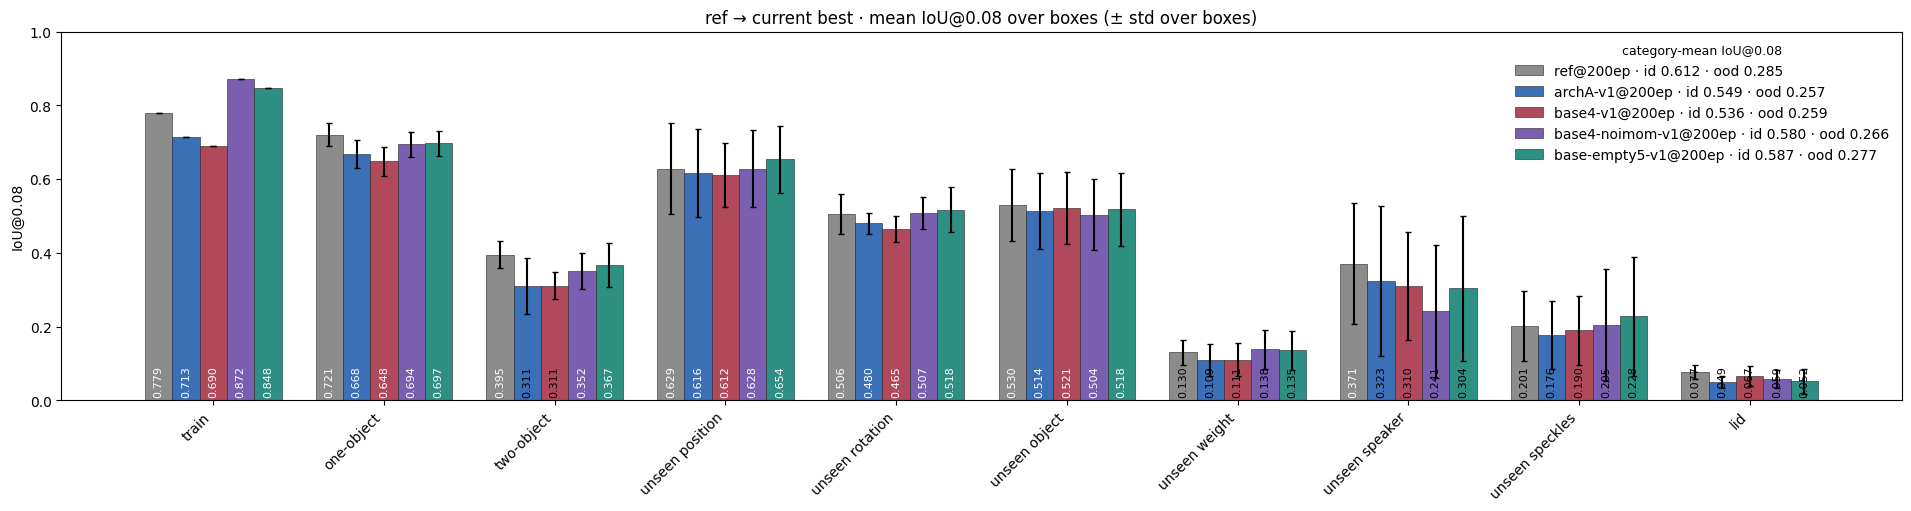

ref → base-empty5-v1: mean Δ split IoU -0.018, Δ miss +0.034
  per box  ΔIoU: gastro -0.014  plastic +0.016  cardboard -0.045 | Δmiss: gastro +0.042  plastic +0.014  cardboard +0.045
  per cat  ΔIoU: unseen-rotated-object -0.147  broken -0.133  unseen-angle -0.071  unseen-speaker -0.067  multiple -0.028  unseen-object -0.026  control -0.026  lid -0.025  id -0.024  rotated -0.000  cylinder +0.005  unseen-position +0.025  unseen-laser +0.027
  worst: cardboard/glass-cup 0.55→0.40 (-0.148); cardboard/portable-charger-sideways 0.38→0.23 (-0.147); cardboard/portable-charger 0.29→0.15 (-0.143)
  best:  plastic/cube-shifted-lasers-2 0.31→0.41 (+0.099); gastro/cube-without-lid 0.45→0.55 (+0.092); plastic/cube-shifted-lasers-1 0.42→0.51 (+0.082)
  unseen speaker: gastro/cube-unseen-speaker-unseen 0.20→0.11 (-0.086); plastic/cube-unseen-speaker-unseen 0.52→0.50 (-0.015); cardboard/vase-unseen-speaker-unseen 0.40→0.30 (-0.100)


In [21]:
plot_runs([REF, "archA-v1", "base4-v1", "base4-noimom-v1", "base-empty5-v1"], "ref → current best")
exceptions(REF, "base-empty5-v1")

**The current best `base-empty5-v1` (.655 / .364) is still below the reference (.679 / .377) on IoU** — −.024 ID, −.013 OOD, with miss .184 vs .150 and per-split IoU .409 vs .427 — at 37% fewer params (21.9M vs 34.9M). The simplifications made the model smaller and box-free in its inputs (except the 5-scan calibration), not better.

**Where the gap to the ref is:** cardboard (−.045) and gastro (−.014); plastic is *above* the ref (+.016). By category, the losses are unseen rotated object (−.147), broken (−.133), unseen-angle (−.071) and unseen speaker (−.067: cardboard .40 → .30, gastro .20 → .11); worst splits cardboard glass-cup −.148, portable-charger-sideways −.147, portable-charger −.143. The current model beats the ref on unseen speckles (+.027; plastic cube-shifted-lasers-2 +.099, -1 +.082) and unseen position (+.025).